# Lab 02 · 그래디언트 부스팅을 직접 만들고, XGBoost·LightGBM·SHAP 써 보기

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | "잔차에 작은 트리를 계속 더한다"를 30줄로 구현 | Friedman (2001) *Greedy Function Approximation* |
| 2 | 배깅(분산↓)과 부스팅(편향↓)의 차이 | Breiman (2001) *Random Forests* |
| 3 | XGBoost의 분할 이득(gain) 공식을 손으로 계산 | Chen & Guestrin (2016) *XGBoost* |
| 4 | 조기 종료(early stopping)로 트리 수 정하기 | XGBoost, LightGBM (2017) |
| 5 | 순열 중요도와 SHAP, SHAP의 가법성(additivity) 확인 | Lundberg & Lee (2017) *SHAP* |

**소요 시간**: 90분 · **패키지**: numpy, pandas, matplotlib, scikit-learn, xgboost, lightgbm, shap  
Colab에서 없으면: `!pip install -q xgboost lightgbm shap`

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (7, 3.5), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 그래디언트 부스팅을 밑바닥부터 (Friedman, 2001)

알고리즘 전체는 이것뿐입니다.

1. 예측을 상수(평균)로 시작한다: $F_0(x)=\bar y$
2. 반복: 현재 예측의 **잔차** $r = y - F(x)$ 를 계산하고, 얕은 트리 $h$ 를 잔차에 맞춘 뒤, 조금만 더한다: $F \leftarrow F + \eta\,h$

제곱 손실 $L=\frac12(y-F)^2$ 에서 잔차는 손실의 **음의 기울기** $-\partial L/\partial F$ 와 같습니다. 그래서 "함수 공간에서의 경사하강"이라고 부릅니다.

✍️ **예측**: 학습률 $\eta$ 를 1.0으로 할 때와 0.1로 할 때, 트리 수에 따른 test 오차 곡선은 어떻게 다를까요?

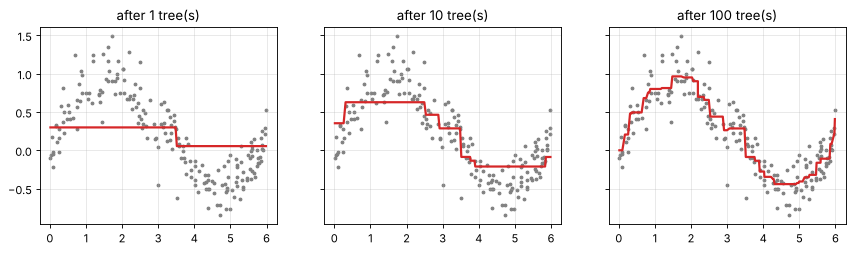

In [2]:
class MyGBM:
    """제곱 손실용 그래디언트 부스팅 (교육용 최소 구현)"""
    def __init__(self, n_rounds=100, lr=0.1, max_depth=2):
        self.n_rounds, self.lr, self.max_depth = n_rounds, lr, max_depth
    def fit(self, X, y):
        self.f0 = y.mean()
        self.trees = []
        F = np.full(len(y), self.f0)
        for _ in range(self.n_rounds):
            residual = y - F                                   # 음의 기울기
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, residual)
            F += self.lr * tree.predict(X)                     # 조금만 더한다 (shrinkage)
            self.trees.append(tree)
        return self
    def staged_predict(self, X):
        F = np.full(len(X), self.f0)
        for tree in self.trees:
            F = F + self.lr * tree.predict(X)
            yield F
    def predict(self, X):
        for F in self.staged_predict(X): pass
        return F

# 1차원 예제: 단계별로 예측이 어떻게 만들어지는지 눈으로 보기
x1 = np.sort(rng.uniform(0, 6, 200)); y1 = np.sin(x1) + 0.5 * (x1 > 3) + rng.normal(0, 0.2, 200)
gbm = MyGBM(n_rounds=100, lr=0.3, max_depth=1).fit(x1[:, None], y1)
stages = list(gbm.staged_predict(x1[:, None]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, k in zip(axes, [1, 10, 100]):
    ax.scatter(x1, y1, s=6, c="gray"); ax.plot(x1, stages[k - 1], c="tab:red", lw=2); ax.set_title(f"after {k} tree(s)")
plt.show()

깊이 1짜리 트리(계단 하나)를 더할 뿐인데, 100번 쌓으면 곡선을 따라갑니다. 이제 진짜 표 형태 데이터로 옮겨 학습률의 효과를 봅니다.  
데이터는 Friedman이 직접 만든 벤치마크 함수(`make_friedman1`)입니다: $y = 10\sin(\pi x_0 x_1) + 20(x_2-0.5)^2 + 10x_3 + 5x_4 + \varepsilon$. 특성 10개 중 **뒤의 5개는 y와 무관**합니다.

lr=1.0: 가장 낮은 test MSE = 4.30 (트리 23개일 때), 300개일 때 = 5.21


lr=0.1: 가장 낮은 test MSE = 1.95 (트리 280개일 때), 300개일 때 = 1.95


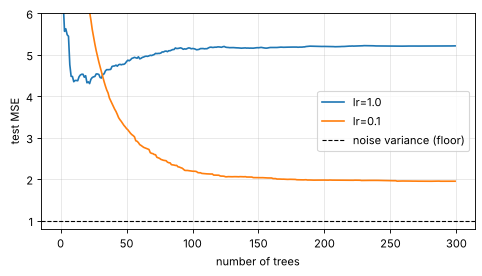

직접 구현 test MSE = 1.958   scikit-learn GBM test MSE = 1.953


In [3]:
from sklearn.datasets import make_friedman1
X, y = make_friedman1(n_samples=3000, n_features=10, noise=1.0, random_state=0)
cols = [f"x{i}" for i in range(10)]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=0)
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.25, random_state=0)

plt.figure(figsize=(7, 3.5))
for lr in [1.0, 0.1]:
    m = MyGBM(n_rounds=300, lr=lr, max_depth=3).fit(X_fit, y_fit)
    curve = [mean_squared_error(y_te, p) for p in m.staged_predict(X_te)]
    plt.plot(curve, label=f"lr={lr}")
    print(f"lr={lr}: 가장 낮은 test MSE = {min(curve):.2f} (트리 {int(np.argmin(curve)) + 1}개일 때), 300개일 때 = {curve[-1]:.2f}")
plt.axhline(1.0, color="k", ls="--", lw=1, label="noise variance (floor)")
plt.ylim(0.8, 6); plt.xlabel("number of trees"); plt.ylabel("test MSE"); plt.legend(); plt.show()

mine = MyGBM(n_rounds=300, lr=0.1, max_depth=3).fit(X_fit, y_fit)
ref = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0).fit(X_fit, y_fit)
print(f"직접 구현 test MSE = {mean_squared_error(y_te, mine.predict(X_te)):.3f}   scikit-learn GBM test MSE = {mean_squared_error(y_te, ref.predict(X_te)):.3f}")

- 학습률이 크면 빨리 내려가지만 일찍 과적합하고 최저점이 높습니다. 학습률을 줄이면 트리가 더 많이 필요하지만 **더 낮은 오차**에 도달합니다. Friedman 논문이 shrinkage를 권한 이유입니다.
- 직접 구현과 scikit-learn의 결과가 거의 같습니다. 30줄이 알고리즘의 본체라는 뜻입니다. XGBoost·LightGBM은 여기에 **정규화된 목적함수, 2차 근사, 빠른 분할 탐색, 시스템 최적화**를 더한 것입니다.

## 2. 배깅과 부스팅 (Breiman, 2001 vs Friedman, 2001)

✍️ **예측**: 깊은 트리 1개 / 랜덤 포레스트(깊은 트리 300개 평균) / 부스팅(얕은 트리 300개 합) 중 test 오차가 가장 낮은 것은?

In [4]:
models = {
    "single deep tree": DecisionTreeRegressor(random_state=0),
    "random forest (300 deep trees)": RandomForestRegressor(300, n_jobs=-1, random_state=0),
    "boosting (300 shallow trees)": GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0),
}
rows = []
for name, m in models.items():
    m.fit(X_fit, y_fit)
    rows.append(dict(model=name, train_mse=mean_squared_error(y_fit, m.predict(X_fit)), test_mse=mean_squared_error(y_te, m.predict(X_te))))
pd.DataFrame(rows).round(2)

,model,train_mse,test_mse
0,single deep tree,0.00,9.10
1,random forest (300 deep trees),0.52,3.61
2,boosting (300 shallow trees),0.36,1.95


- 깊은 트리 하나는 train 오차 0, test 오차는 큼 → 분산이 큰 모델.
- **랜덤 포레스트**는 그런 트리를 서로 다르게(부트스트랩 표본 + 무작위 특성) 여러 개 만들어 **평균**해서 분산을 줄입니다.
- **부스팅**은 편향이 큰 얕은 트리를 **순차적으로** 더해 편향을 줄입니다. 이 데이터처럼 신호가 분명한 정형 데이터에서는 부스팅이 대체로 더 낮은 오차를 냅니다.

## 3. XGBoost의 분할 이득 공식을 손으로 계산하기 (Chen & Guestrin, 2016)

XGBoost는 손실을 2차까지 근사합니다. 각 표본의 1차 기울기 $g_i$, 2차 기울기 $h_i$ 를 구하고, 한 노드를 왼쪽(L)·오른쪽(R)으로 나눌 때의 이득을 다음으로 계산합니다.

$$\text{Gain}=\frac12\left[\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right]-\gamma,\qquad G=\sum g_i,\; H=\sum h_i$$

제곱 손실에서는 $g_i = F(x_i)-y_i$, $h_i=1$ 입니다. 아래에서 한 특성의 모든 분할 후보에 대해 이 값을 계산합니다.

✍️ **예측**: $\lambda=0,\ \gamma=0$ 이면 이 공식이 고르는 분할은 보통의 회귀 트리(분산 감소 기준)가 고르는 분할과 같을까요, 다를까요?

In [5]:
def best_split_by_gain(x, g, h, lam=0.0, gamma=0.0):
    order = np.argsort(x); xs, gs, hs = x[order], g[order], h[order]
    GL, HL = np.cumsum(gs)[:-1], np.cumsum(hs)[:-1]            # 왼쪽에 i+1개를 보냈을 때의 합
    G, H = gs.sum(), hs.sum(); GR, HR = G - GL, H - HL
    gain = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam)) - gamma
    valid = xs[1:] != xs[:-1]                                    # 같은 값 사이에서는 나눌 수 없다
    i = int(np.argmax(np.where(valid, gain, -np.inf)))
    return (xs[i] + xs[i + 1]) / 2, gain[i]

F0 = np.full(len(y_fit), y_fit.mean())
g, h = F0 - y_fit, np.ones(len(y_fit))                           # 제곱 손실의 1차·2차 기울기
results = [(c, *best_split_by_gain(X_fit[:, j], g, h)) for j, c in enumerate(cols)]
table = pd.DataFrame(results, columns=["feature", "threshold", "gain"]).sort_values("gain", ascending=False)
print(table.head(4).round(3).to_string(index=False))

stump = DecisionTreeRegressor(max_depth=1).fit(X_fit, y_fit)
print(f"\nscikit-learn 깊이 1 트리가 고른 분할: {cols[stump.tree_.feature[0]]} <= {stump.tree_.threshold[0]:.3f}")

feature  threshold     gain
     x3      0.416 3721.850
     x0      0.218 2430.758
     x1      0.386 2305.998
     x4      0.352 1012.679

scikit-learn 깊이 1 트리가 고른 분할: x3 <= 0.416


$\lambda=0$ 이면 두 기준이 같은 분할을 고릅니다(제곱 손실에서 이득 공식은 SSE 감소량의 절반과 같습니다).  
XGBoost가 더한 것은 (1) **$\lambda$**: 잎의 값을 0 쪽으로 줄여 과적합 억제, (2) **$\gamma$**: 이득이 $\gamma$ 보다 작으면 나누지 않음(가지치기), (3) 임의의 미분 가능한 손실에 같은 공식을 쓸 수 있는 **일반성**입니다. 논문 2절의 식을 이 코드와 한 줄씩 대응시켜 보세요.

## 4. XGBoost · LightGBM 실전 사용: 조기 종료

트리 수는 "많이 주고, 검증 오차가 더 안 내려가면 멈춘다"가 표준입니다. **검증 세트는 test와 별개**여야 합니다(test로 멈출 시점을 정하면 누수).

In [6]:
import xgboost as xgb, lightgbm as lgb
xgb_model = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             reg_lambda=1.0, early_stopping_rounds=50, random_state=0)
xgb_model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

lgb_model = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=0, verbose=-1)
lgb_model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])

print(f"XGBoost : 멈춘 트리 수 = {xgb_model.best_iteration + 1:4d},  test MSE = {mean_squared_error(y_te, xgb_model.predict(X_te)):.3f}")
print(f"LightGBM: 멈춘 트리 수 = {lgb_model.best_iteration_:4d},  test MSE = {mean_squared_error(y_te, lgb_model.predict(X_te)):.3f}")
print("참고: 잡음의 분산(도달 가능한 하한) = 1.0")

XGBoost : 멈춘 트리 수 =  495,  test MSE = 1.748
LightGBM: 멈춘 트리 수 =  338,  test MSE = 1.789
참고: 잡음의 분산(도달 가능한 하한) = 1.0


## 5. 모델 해석: 순열 중요도와 SHAP (Lundberg & Lee, 2017)

이 데이터는 정답을 알고 있습니다. `x0`~`x4`만 영향을 주고 `x5`~`x9`는 무관합니다. 해석 기법이 이를 맞히는지 봅니다.

- **순열 중요도**: 한 특성의 값을 섞었을 때 성능이 얼마나 나빠지는가 (전역, 모델 무관)
- **SHAP**: 각 예측을 "기준값 + 특성별 기여도의 합"으로 분해 (개별 예측 단위)

✍️ **예측**: SHAP 값들을 한 행에서 모두 더하면 무엇이 될까요?

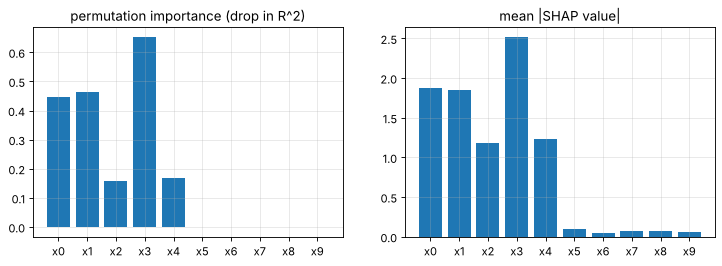

기준값 + SHAP 합  vs  모델 예측의 최대 차이 = 5.3290705182007514e-14

0번 표본: 예측 16.98 = 기준값 14.15 + -1.38(x0) + +1.88(x1) + -0.27(x2) + +3.48(x3) + -1.02(x4) + ...


In [7]:
import shap
from sklearn.inspection import permutation_importance
perm = permutation_importance(lgb_model, X_te, y_te, n_repeats=5, random_state=0)
explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer.shap_values(X_te)                          # (표본 수, 특성 수)
base_value = float(np.ravel(explainer.expected_value)[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(cols, perm.importances_mean); axes[0].set_title("permutation importance (drop in R^2)")
axes[1].bar(cols, np.abs(shap_values).mean(axis=0)); axes[1].set_title("mean |SHAP value|")
plt.show()

recon = base_value + shap_values.sum(axis=1)                       # 가법성: 기준값 + 기여도 합
print("기준값 + SHAP 합  vs  모델 예측의 최대 차이 =", float(np.max(np.abs(recon - lgb_model.predict(X_te)))))
i = 0
print(f"\n0번 표본: 예측 {lgb_model.predict(X_te[[i]])[0]:.2f} = 기준값 {base_value:.2f} + " + " + ".join(f"{v:+.2f}({c})" for c, v in zip(cols[:5], shap_values[i, :5])) + " + ...")

- 두 방법 모두 `x0`~`x4`를 중요하다고, `x5`~`x9`를 거의 0으로 평가합니다.
- **가법성(local accuracy)**: 기준값(평균 예측) + 그 행의 SHAP 값 합 = 그 행의 예측. 논문이 요구하는 세 성질 중 첫 번째이며, 위에서 차이가 수치 오차 수준임을 확인했습니다.

SHAP 값을 특성 값에 대해 그리면 모델이 배운 **함수의 모양**이 보입니다.

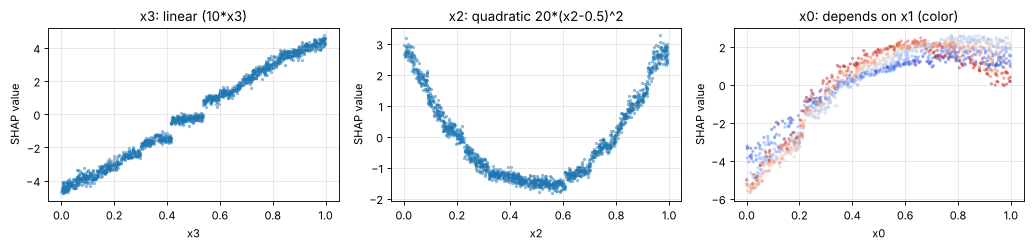

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, j in zip(axes, [3, 2, 0]):
    ax.scatter(X_te[:, j], shap_values[:, j], s=4, alpha=0.4, c=X_te[:, 1] if j == 0 else "tab:blue", cmap="coolwarm")
    ax.set_xlabel(cols[j]); ax.set_ylabel("SHAP value")
axes[0].set_title("x3: linear (10*x3)"); axes[1].set_title("x2: quadratic 20*(x2-0.5)^2"); axes[2].set_title("x0: depends on x1 (color)")
plt.tight_layout(); plt.show()

`x3`은 직선, `x2`는 포물선, `x0`은 `x1`의 값(색)에 따라 기여도가 갈라집니다(상호작용 $\sin(\pi x_0x_1)$). 데이터를 만든 식과 일치합니다.

**주의**: SHAP은 "모델이 무엇을 쓰는가"를 설명할 뿐 **인과 효과가 아닙니다**. 상관된 특성이 있으면 기여도가 나뉘고, 모델이 틀리면 설명도 틀립니다 (Rudin, 2018의 비판 참고).

---
## 직접 해보기

1. **(다른 손실)** `MyGBM`을 절대 손실(L1)용으로 바꾸세요. 음의 기울기는 `np.sign(y - F)` 입니다. y의 5%에 큰 이상치(+50)를 넣은 데이터에서 제곱 손실 버전과 test MAE를 비교하세요.
2. **(정규화)** XGBoost에서 `max_depth`를 2, 4, 8로 바꾸며 조기 종료된 트리 수와 test MSE가 어떻게 변하는지 표로 만드세요.
3. **(해석의 한계)** `x3`과 거의 같은 값을 갖는 복제 특성 `x3_copy = x3 + 작은 잡음`을 추가해 다시 학습하면 `x3`의 순열 중요도와 SHAP 중요도는 어떻게 될까요? 먼저 예측한 뒤 확인하세요.

In [9]:
# TODO 1: L1 손실용 부스팅

# TODO 2: max_depth 에 따른 변화

# TODO 3: 복제 특성 추가

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [10]:
# 1. L1 손실: 트리는 sign(잔차)에 맞추고, 시작값은 평균 대신 중앙값
class MyGBM_L1(MyGBM):
    def fit(self, X, y):
        self.f0 = np.median(y); self.trees = []
        F = np.full(len(y), self.f0)
        for _ in range(self.n_rounds):
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, np.sign(y - F))
            F += self.lr * tree.predict(X); self.trees.append(tree)
        return self

y_out = y_fit.copy(); bad = rng.random(len(y_out)) < 0.05; y_out[bad] += 50      # 학습 라벨의 5%를 오염
mae = lambda m: np.mean(np.abs(y_te - m.predict(X_te)))
l2 = MyGBM(300, 0.1, 3).fit(X_fit, y_out); l1 = MyGBM_L1(600, 0.1, 3).fit(X_fit, y_out)
print(f"오염된 라벨로 학습 → test MAE   제곱 손실: {mae(l2):.2f}   절대 손실: {mae(l1):.2f}")

오염된 라벨로 학습 → test MAE   제곱 손실: 3.77   절대 손실: 1.22


In [11]:
# 2. max_depth 에 따른 변화
rows = []
for d in [2, 4, 8]:
    m = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.05, max_depth=d, early_stopping_rounds=50, random_state=0)
    m.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    rows.append(dict(max_depth=d, trees=m.best_iteration + 1, test_mse=round(mean_squared_error(y_te, m.predict(X_te)), 3)))
pd.DataFrame(rows)

,max_depth,trees,test_mse
0,2,560,2.082
1,4,571,1.932
2,8,407,3.092


In [12]:
# 3. 복제 특성: 중요도가 두 특성으로 나뉜다
X_dup_fit = np.c_[X_fit, X_fit[:, 3] + rng.normal(0, 0.01, len(X_fit))]
X_dup_te = np.c_[X_te, X_te[:, 3] + rng.normal(0, 0.01, len(X_te))]
m_dup = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, colsample_bytree=0.8, random_state=0, verbose=-1).fit(X_dup_fit, y_fit)
sv = shap.TreeExplainer(m_dup).shap_values(X_dup_te)
pi = permutation_importance(m_dup, X_dup_te, y_te, n_repeats=5, random_state=0).importances_mean
print("mean|SHAP|   x3 = %.2f, x3_copy = %.2f   (복제 전 x3 = %.2f)" % (np.abs(sv[:, 3]).mean(), np.abs(sv[:, 10]).mean(), np.abs(shap_values[:, 3]).mean()))
print("순열 중요도   x3 = %.2f, x3_copy = %.2f   (복제 전 x3 = %.2f)" % (pi[3], pi[10], perm.importances_mean[3]))

mean|SHAP|   x3 = 1.44, x3_copy = 1.16   (복제 전 x3 = 2.51)
순열 중요도   x3 = 0.20, x3_copy = 0.15   (복제 전 x3 = 0.65)


**해석**
- 1번: 제곱 손실은 이상치를 맞추려고 예측 전체가 끌려가지만, 절대 손실은 기울기 크기가 ±1로 제한되어 훨씬 덜 흔들립니다. Friedman 논문이 여러 손실(LS, LAD, Huber)을 다룬 이유입니다.
- 3번: 같은 정보를 가진 특성이 둘이면 중요도가 **나뉘어** 각각 작아 보입니다. "중요도가 낮다 = 쓸모없는 변수"가 아닙니다. 상관된 특성 묶음은 함께 해석해야 합니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 1절 `MyGBM` | Friedman (2001)의 일반 알고리즘(Gradient Boost)과 shrinkage 실험 |
| 3절 이득 공식 | XGBoost 논문 2절: 정규화된 목적함수 → 2차 근사 → 잎의 최적값 → 분할 이득 |
| 4절 | XGBoost 3절(근사 분할, 희소성 처리)·4절(시스템), LightGBM의 GOSS·EFB가 "무엇을 빠르게 하려는 것인지" |
| 5절 가법성 | SHAP 논문의 세 성질(local accuracy, missingness, consistency)과 Tree SHAP |

## 기억 점검

1. 그래디언트 부스팅에서 새 트리는 무엇을 목표값으로 학습하나? 왜 "gradient"인가?
2. 학습률(shrinkage)을 낮추면 얻는 것과 잃는 것은?
3. 배깅과 부스팅은 각각 편향·분산 중 무엇을 주로 줄이나?
4. XGBoost 이득 공식의 $\lambda$ 와 $\gamma$ 는 각각 어떤 역할인가?
5. SHAP의 가법성이란? SHAP 값이 크다는 것이 인과 효과를 뜻하지 않는 이유는?

<details><summary>답 확인</summary>

1. 현재 예측에 대한 손실의 음의 기울기(제곱 손실이면 잔차). 예측 함수를 손실이 줄어드는 방향으로 조금씩 옮기므로 함수 공간의 경사하강.
2. 더 낮은 test 오차·안정적 학습을 얻고, 더 많은 트리(계산 시간)가 필요해진다.
3. 배깅(랜덤 포레스트)은 분산, 부스팅은 편향.
4. λ: 잎 값에 대한 L2 벌점(값을 0 쪽으로 축소). γ: 잎을 하나 늘리는 비용 — 이득이 γ보다 작으면 분할하지 않는다.
5. 기준값 + 특성별 SHAP 합 = 예측. SHAP은 모델의 계산을 분해한 것이지 현실의 개입 효과가 아니며, 상관된 특성·교란변수가 있으면 기여도가 실제 원인과 어긋난다.
</details>